# Segmentación de miotubos
EDA, auditoría de particiones y línea base clásica en `vt`.

**Unidad de predicción:** píxel de una imagen de microscopía en escala de grises. La etiqueta vale **1** dentro de la unión de los polígonos anotados de miotubos y **0** en el fondo. COCO documenta una categoría de primer plano y las máscaras ya rasterizadas son el objetivo. Un píxel de regiones superpuestas conserva la etiqueta 1. La matriz de confusión tiene las dos clases disponibles.

**Fuente:** `vt/vt`. La carpeta contiene COCO, YOLO y PNG. Al faltar los CSV originales, se exporta un catálogo desde COCO y se relee como entrada del pipeline. `subset_10GB` queda reservado para inferencia opcional.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image as NotebookImage, display
from PIL import Image

from baseline import curves, evaluate, score_histograms
from pipeline import SEED, audit_and_split, coco_to_csv, read_manifest
from plots import histogram, overlay_panel, precision_recall

root = Path("vt/vt")
out = Path("resultados")
figures = out / "figuras"
figures.mkdir(parents=True, exist_ok=True)
source_csv = out / "catalogo_coco.csv"

coco_to_csv(root, source_csv)
audit = audit_and_split(root, source_csv, out, seed=SEED)
train, val = [read_manifest(out / f"{split}.csv") for split in ("train", "val")]
stats = pd.read_csv(out / "image_stats.csv")
catalog = pd.read_csv(source_csv).merge(stats, on="image_id", validate="one_to_one")
catalog["foreground_pct"] = 100 * catalog["positive"] / catalog["pixels"]
catalog["contrast"] = catalog["p95"] - catalog["p05"]
print(f"{len(catalog)} pares | {len(train)} entrenamiento | {len(val)} validación")
display(pd.DataFrame([audit]))

306 pares | 245 entrenamiento | 61 validación


,seed,val_fraction,original_groups,train_groups,val_groups,exact_pairs,near_pairs,cross_pairs,train_only_group
0,2026,0.2,31,26,5,13,0,0,origen-no-confirmado


## Integridad de las etiquetas y fuga de información

El prefijo UUID compartido de los nombres con sufijo `*_Best` se usa como proxy de serie. Las imágenes sin un UUID reconocible se agrupan y quedan en entrenamiento. Se unen grupos que comparten imágenes idénticas (SHA-256 de píxeles) o candidatos visualmente muy cercanos (dHash de 1,024 bits con distancia de Hamming ≤ 24). La partición 80/20 se fija con semilla 2026 y equilibra aproximadamente el tamaño, la prevalencia y las máscaras vacías por grupo.

Un cruce de grupos o pares detectados paraliza el pipeline. El nombre de archivo y el dHash tienen alcance limitado. La independencia por pozo, día o muestra sigue sin verificarse con metadatos experimentales. Tampoco se cubren recortes, rotaciones o campos parcialmente superpuestos.

In [2]:
matched = {Path(name).stem for name in catalog["image"]}
image_stems = {p.stem for p in (root / "images").glob("*.png")}
mask_stems = {p.stem for p in (root / "masks_png").glob("*.png")}
overlays = {p.stem for p in (root / "verification").glob("*.png")}
label_stems = {p.stem for p in (root / "labels").glob("*.txt")}
assert matched == image_stems == mask_stems
assert all(row["image_id"] != "" for row in train + val)

count_mismatches = []
bad_polygons = []
for row in catalog.itertuples():
    stem = Path(row.image).stem
    path = root / "labels" / f"{stem}.txt"
    if not path.is_file():
        count_mismatches.append(stem)
        continue
    lines = [line.split() for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]
    if len(lines) != row.instances:
        count_mismatches.append(stem)
    for line in lines:
        coords = np.array(line[1:], dtype=float)
        if line[0] != "0" or len(coords) < 6 or len(coords) % 2 or not np.all((0 <= coords) & (coords <= 1)):
            bad_polygons.append(stem)

pairs = pd.read_csv(out / "similar_pairs.csv")
exact = pairs[pairs["exact"]].copy()
validation_names = {r["image"] for r in val}
mask_ious = []
for pair in exact.itertuples():
    masks = []
    for name in (pair.image_a, pair.image_b):
        with Image.open(root / "masks_png" / Path(name).name) as img:
            masks.append(np.asarray(img) > 0)
    union = np.count_nonzero(masks[0] | masks[1])
    intersection = np.count_nonzero(masks[0] & masks[1])
    mask_ious.append(intersection / union if union else 1.0)
exact["mask_iou"] = mask_ious
exact["particion"] = exact["image_a"].map(lambda name: "validación" if name in validation_names else "entrenamiento")

integrity = {
    "images": len(catalog), "height": int(catalog["height"].iloc[0]), "width": int(catalog["width"].iloc[0]),
    "instances": int(catalog["instances"].sum()), "extra_yolo": len(label_stems - matched),
    "yolo_count_mismatches": len(count_mismatches), "irregular_yolo_polygons": len(bad_polygons),
    "missing_overlays": len(matched - overlays),
    "unknown_origin": int((catalog["group_id"] == "origen-no-confirmado").sum()),
    "exact_pairs_with_different_masks": int((exact["mask_iou"] < 1).sum()),
    "exact_mask_iou_min": float(exact["mask_iou"].min()) if len(exact) else None,
    "exact_mask_iou_max": float(exact["mask_iou"].max()) if len(exact) else None,
    "exact_pairs_val": int((exact["particion"] == "validación").sum()),
}
(out / "integridad.json").write_text(json.dumps(integrity, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(pd.Series(integrity, name="Resultado").to_frame())
display(exact[["mask_iou", "particion"]].describe(include="all"))

,Resultado
images,306.000000
height,1944.000000
width,2592.000000
instances,2118.000000
extra_yolo,12.000000
yolo_count_mismatches,28.000000
irregular_yolo_polygons,30.000000
missing_overlays,0.000000
unknown_origin,52.000000
exact_pairs_with_different_masks,13.000000


,mask_iou,particion
count,13.000000,13
unique,NaN,1
top,NaN,entrenamiento
freq,NaN,13
mean,0.317128,NaN
std,0.105362,NaN
min,0.146161,NaN
25%,0.284126,NaN
50%,0.305492,NaN
75%,0.341103,NaN


## Análisis exploratorio y desbalance

La tabla cuenta todos los píxeles de cada partición, incluidas las máscaras vacías válidas. Las gráficas descriptivas de intensidad, cobertura e instancias se calculan sobre entrenamiento. El panel usa una muestra aleatoria reproducible de seis pares y superpone las máscaras en turquesa. El contraste es el rango robusto P95 − P05 de niveles de gris.

In [3]:
by_split = {"Total vt": catalog, "Entrenamiento": catalog[~catalog["image"].isin(validation_names)],
            "Validación": catalog[catalog["image"].isin(validation_names)]}
imbalance_rows = []
for name, selection in by_split.items():
    positive, pixels = selection[["positive", "pixels"]].sum()
    imbalance_rows.append(dict(
        particion=name, imagenes=len(selection), vacias=int((selection["positive"] == 0).sum()),
        fondo=int(pixels - positive), miotubo=int(positive),
        fondo_pct=100 * (pixels - positive) / pixels, miotubo_pct=100 * positive / pixels,
    ))
imbalance = pd.DataFrame(imbalance_rows)
imbalance.to_csv(out / "desbalance.csv", index=False, lineterminator="\n")
display(imbalance.round(3))

analysis = by_split["Entrenamiento"]
description = analysis[["foreground_pct", "instances", "contrast"]].describe(percentiles=[.1, .5, .9])
description.to_csv(out / "resumen_eda.csv", lineterminator="\n")
display(description.round(3))

,particion,imagenes,vacias,fondo,miotubo,fondo_pct,miotubo_pct
0,Total vt,306,34,1514758786,27128702,98.241,1.759
1,Entrenamiento,245,27,1213034674,21483086,98.260,1.740
2,Validación,61,7,301724112,5645616,98.163,1.837


,foreground_pct,instances,contrast
count,245.000,245.000,245.000
mean,1.740,7.237,115.731
std,5.797,6.071,22.305
min,0.000,0.000,83.000
10%,0.000,0.000,97.400
50%,0.900,6.000,109.000
90%,2.543,16.000,146.000
max,72.788,34.000,193.000


Cobertura de miotubo


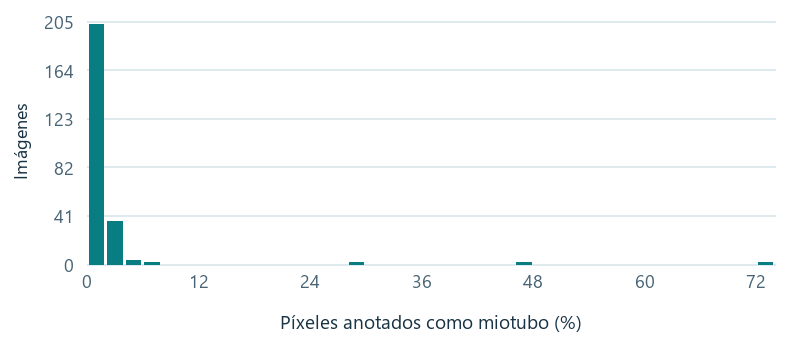

Instancias por imagen


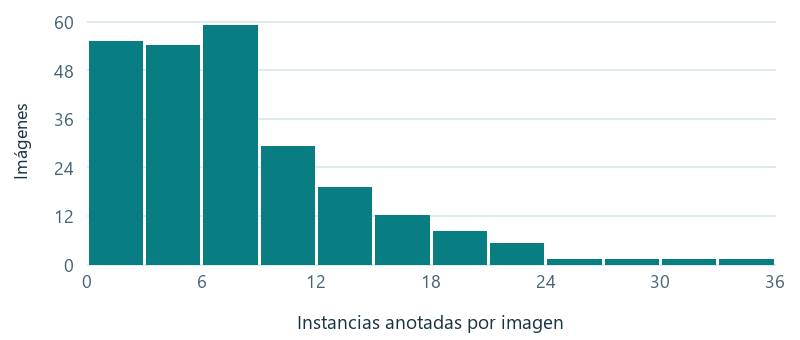

Contraste por imagen


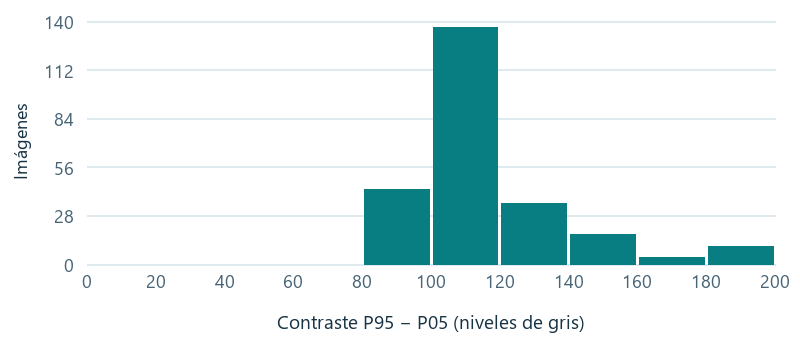

Auditoría visual de seis pares


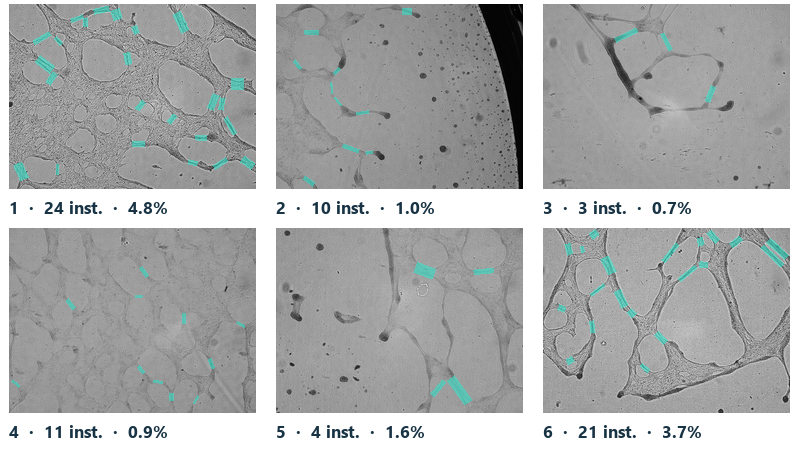

,caption,image,mask
0,1 · 24 inst. · 4.8%,images/22d32863-cell12.png,masks_png/22d32863-cell12.png
1,2 · 10 inst. · 1.0%,images/3d26f913-fc183976-b90b-42f5-b0f5-3142ad...,masks_png/3d26f913-fc183976-b90b-42f5-b0f5-314...
2,3 · 3 inst. · 0.7%,images/e8b3420d-35f892c1-da41-4a26-afbf-cb846c...,masks_png/e8b3420d-35f892c1-da41-4a26-afbf-cb8...
3,4 · 11 inst. · 0.9%,images/25989164-fc183976-b90b-42f5-b0f5-3142ad...,masks_png/25989164-fc183976-b90b-42f5-b0f5-314...
4,5 · 4 inst. · 1.6%,images/61adc5e7-35f892c1-da41-4a26-afbf-cb846c...,masks_png/61adc5e7-35f892c1-da41-4a26-afbf-cb8...
5,6 · 21 inst. · 3.7%,images/495e66bd-cell19.png,masks_png/495e66bd-cell19.png


In [4]:
histogram(analysis["foreground_pct"], np.arange(0, 2 * np.ceil(analysis["foreground_pct"].max() / 2) + 2, 2),
          "Píxeles anotados como miotubo (%)", figures / "cobertura.png")
histogram(analysis["instances"], np.arange(0, 3 * np.ceil((analysis["instances"].max() + 1) / 3) + 3, 3),
          "Instancias anotadas por imagen", figures / "instancias.png")
histogram(analysis["contrast"], np.arange(0, 20 * np.ceil(analysis["contrast"].max() / 20) + 20, 20),
          "Contraste P95 − P05 (niveles de gris)", figures / "contraste.png")
sample = analysis.sample(n=6, random_state=SEED).to_dict("records")
for i, row in enumerate(sample, 1):
    row["caption"] = f'{i}  ·  {row["instances"]} inst.  ·  {row["foreground_pct"]:.1f}%'
overlay_panel(root, sample, figures / "superposiciones.png")

for key, title in [
    ("cobertura", "Cobertura de miotubo"), ("instancias", "Instancias por imagen"),
    ("contraste", "Contraste por imagen"), ("superposiciones", "Auditoría visual de seis pares")]:
    print(title)
    display(NotebookImage(filename=str(figures / f"{key}.png")))
display(pd.DataFrame(sample)[["caption", "image", "mask"]])

## Línea base clásica

Dos suavizados gaussianos (radios 2 y 28 píxeles) estiman el detalle y el fondo local. Se restan ambos y se comparan tres puntuaciones (detalle claro, oscuro y magnitud absoluta). La variante se elige por PR-AUC en entrenamiento. El umbral sobre ese mapa produce la máscara binaria. Las puntuaciones enteras conservan el orden de contraste y permiten calcular las curvas de todos los píxeles mediante histogramas de 256 niveles por clase.

In [5]:
train_histograms = score_histograms(root, train)
ranking = {name: curves(counts)["average_precision"] for name, counts in train_histograms.items()}
variant = max(ranking, key=ranking.get)
print(f"Variante elegida en entrenamiento: {variant}")
display(pd.Series(ranking, name="PR-AUC (AP)").to_frame().round(5))

Variante elegida en entrenamiento: absoluto


,PR-AUC (AP)
claro,0.02402
oscuro,0.03390
absoluto,0.04080


## Validación

La PR-AUC se calcula como *average precision* (AP, suma escalonada) y la ROC-AUC por integración trapezoidal. Ambas son microagregadas sobre píxeles. Para el recall a precisión ≥ 0.80 se recorren umbrales con alguna predicción positiva. Si la meta es inalcanzable, se documenta y se usa el umbral de máximo Dice en validación para ilustrar la matriz. El umbral se selecciona con esta misma validación, por lo que la matriz describe un punto operativo exploratorio.

,Validación
pr_auc,0.042932
roc_auc,0.693892
prevalence,0.018368
precision_target,0.8
recall_at_precision_080,None
threshold,15
precision,0.066484
recall,0.258233
predicted_positive,21928241
criterion,maximo Dice en validacion


,Predicho: fondo,Predicho: miotubo
Real: fondo,281253758,20470354
Real: miotubo,4187729,1457887


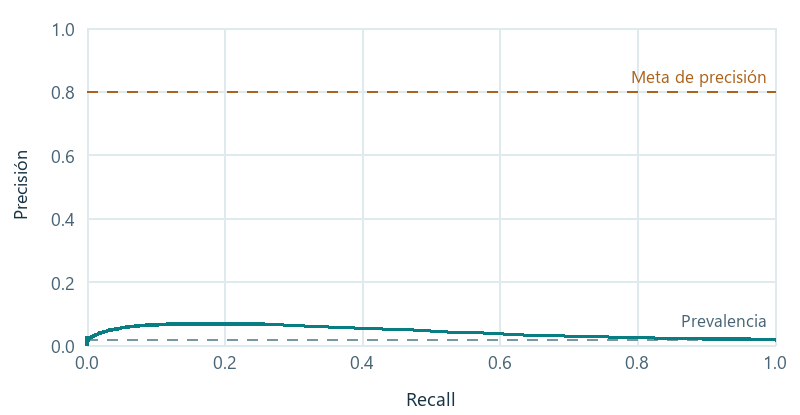

In [6]:
counts = score_histograms(root, val, (variant,))[variant]
metrics = evaluate(counts)
metrics.update(variant=variant, train_pr_auc=ranking)
valid_stats = by_split["Validación"]
assert counts[0].sum() == int((valid_stats["pixels"] - valid_stats["positive"]).sum())
assert counts[1].sum() == int(valid_stats["positive"].sum())
assert sum(map(sum, metrics["confusion"])) == counts.sum()
(out / "metricas_validacion.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")

display(pd.Series({key: value for key, value in metrics.items()
                   if key not in ("confusion", "train_pr_auc")}, name="Validación").to_frame())
display(pd.DataFrame(metrics["confusion"], index=["Real: fondo", "Real: miotubo"],
                     columns=["Predicho: fondo", "Predicho: miotubo"]))
precision_recall(curves(counts), metrics["prevalence"], figures / "precision_recall.png")
display(NotebookImage(filename=str(figures / "precision_recall.png")))

In [7]:
total = imbalance.iloc[0]
print(f"En vt, {total.miotubo_pct:.2f}% de píxeles son miotubo y {total.vacias} de {total.imagenes} imágenes tienen máscara vacía.")
print(f"La mediana de cobertura en entrenamiento es {description.loc['50%', 'foreground_pct']:.2f}%.")
print(f"La auditoría halló {audit['exact_pairs']} pares idénticos y {audit['cross_pairs']} cruces de pares detectados.")
print(f"En validación, AP = {metrics['pr_auc']:.4f} frente a prevalencia {metrics['prevalence']:.4f}.")
if metrics["recall_at_precision_080"] is None:
    print(f"La mayor precisión con predicciones positivas fue {metrics['max_precision']:.2%}. "
          "Ningún umbral alcanzó 80% de precisión.")
else:
    print(f"Recall al alcanzar 80% de precisión: {metrics['recall_at_precision_080']:.2%}.")

En vt, 1.76% de píxeles son miotubo y 34 de 306 imágenes tienen máscara vacía.
La mediana de cobertura en entrenamiento es 0.90%.
La auditoría halló 13 pares idénticos y 0 cruces de pares detectados.
En validación, AP = 0.0429 frente a prevalencia 0.0184.
La mayor precisión con predicciones positivas fue 6.92%. Ningún umbral alcanzó 80% de precisión.
